# Industrial Boiler Operations — Anomaly Detection

This notebook identifies **candidate data and process anomalies** in `data.csv` and `data_AutoReg.csv`, using sensor descriptions from `columns.csv` and the data-quality/time-series context established in `EDA.ipynb`. It combines robust per-sensor outlier screening, local rolling deviations, and multivariate Isolation Forest scores. These are exploratory flags—not alarm limits, fault diagnoses, or proof of unsafe operation. Review flagged periods against operating context and validated engineering limits.

In [11]:
from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import IsolationForest
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import RobustScaler

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 30)

def find_project_root(start=None):
    start = Path.cwd() if start is None else Path(start)
    candidates = [start, *start.parents]
    for candidate in candidates:
        if all((candidate / name).is_file() for name in ("columns.csv", "data.csv", "data_AutoReg.csv", "EDA.ipynb")):
            return candidate
    raise FileNotFoundError("Could not find columns.csv, both data CSVs, and EDA.ipynb in the current folder or a parent.")

PROJECT_DIR = find_project_root()
print(f"Project directory: {PROJECT_DIR}")

Project directory: c:\Users\sulaiman.at\Documents\GitHub\Industrial-Boiler-Operations-Analytics


## 1. Load and align sensor metadata

The EDA found timestamped readings with nominally short sampling intervals and sensor headers carrying a trailing `#`. We preserve source headers, normalize names only for metadata matching, and keep each dataset separate for detection. The EDA notebook's section headings are displayed below to make the prior analysis context visible.

In [12]:
def canonical_name(name):
    return str(name).removesuffix("#")

metadata = pd.read_csv(PROJECT_DIR / "columns.csv")
data = pd.read_csv(PROJECT_DIR / "data.csv", parse_dates=["date"], date_format="mixed")
autoreg = pd.read_csv(PROJECT_DIR / "data_AutoReg.csv", parse_dates=["date"], date_format="mixed")

if not {"Variant", "Description"}.issubset(metadata.columns):
    raise ValueError("columns.csv must contain Variant and Description columns.")
sensor_descriptions = (
    metadata.dropna(subset=["Variant"])
    .assign(_key=lambda frame: frame["Variant"].map(canonical_name))
    .drop_duplicates("_key")
    .set_index("_key")["Description"]
    .to_dict()
)

with (PROJECT_DIR / "EDA.ipynb").open(encoding="utf-8") as file:
    eda_notebook = json.load(file)
eda_headings = [
    line.lstrip("# ")
    for cell in eda_notebook.get("cells", []) if cell.get("cell_type") == "markdown"
    for line in cell.get("source", [])
    if line.startswith("## ")
]
print("EDA context:", " | ".join(eda_headings))
print(f"data.csv: {data.shape[0]:,} rows x {data.shape[1]} columns")
print(f"data_AutoReg.csv: {autoreg.shape[0]:,} rows x {autoreg.shape[1]} columns")
print(f"Sensor metadata entries: {len(sensor_descriptions)}")
display(metadata.head())

EDA context: 1. Load the datasets
 | 2. Schema and measurement descriptions
 | 3. Data quality and time coverage
 | 4. Descriptive statistics
 | 5. Compare the two observation files
 | 6. Visual exploration
 | 7. Automatically generated observations

data.csv: 86,400 rows x 31 columns
data_AutoReg.csv: 86,400 rows x 31 columns
Sensor metadata entries: 30


,Variant,Attribute name,Description
0,PT_8313A.AV_0,Upper furnace pressure (A),NaN
1,PT_8313B.AV_0,Upper furnace pressure (B),NaN
2,PT_8313C.AV_0,Upper furnace pressure (C),NaN
3,PT_8313D.AV_0,Upper furnace pressure (D),NaN
4,PT_8313E.AV_0,Upper furnace pressure (E),NaN


## 2. Detection settings and preparation

The global method uses a robust median/MAD score (with IQR fallback for zero-MAD sensors). The local method compares each reading with a centered 30-minute rolling median and MAD, requiring at least 30 observations; this highlights abrupt changes relative to nearby operation. Isolation Forest finds unusual multivariate combinations. Its contamination is a **screening fraction**, not a known fault prevalence; adjust it after validation. The default 1% is intended to prioritize review.

In [13]:
GLOBAL_MODIFIED_Z_LIMIT = 3.5
LOCAL_MODIFIED_Z_LIMIT = 3.5
ROLLING_WINDOW = "30min"
MIN_ROLLING_OBSERVATIONS = 30
ISOLATION_CONTAMINATION = 0.01
RANDOM_STATE = 42

def prepare_frame(frame):
    prepared = frame.copy()
    if "date" not in prepared.columns:
        raise ValueError("Each observation dataset must contain a 'date' column.")
    prepared["date"] = pd.to_datetime(prepared["date"], errors="coerce")
    prepared = prepared.dropna(subset=["date"]).sort_values("date").reset_index(drop=True)
    sensor_cols = [
        col for col in prepared.columns if col != "date"
        and pd.api.types.is_numeric_dtype(prepared[col])
        and prepared[col].nunique(dropna=True) > 1
    ]
    if not sensor_cols:
        raise ValueError("No varying numeric sensor columns are available for detection.")
    return prepared, sensor_cols

def mad(values):
    median = values.median()
    return (values - median).abs().median()

def robust_global_flags(series):
    center = series.median()
    scale = mad(series)
    if pd.notna(scale) and scale > 0:
        score = 0.67448975 * (series - center) / scale
        return score.abs() > GLOBAL_MODIFIED_Z_LIMIT, score
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    if pd.isna(iqr) or iqr == 0:
        return pd.Series(False, index=series.index), pd.Series(np.nan, index=series.index)
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return (series < lower) | (series > upper), (series - center) / (iqr / 1.349)

prepared_data, data_sensors = prepare_frame(data)
prepared_autoreg, autoreg_sensors = prepare_frame(autoreg)
display(pd.DataFrame({
    "data.csv": {"valid timestamp rows": len(prepared_data), "varying numeric sensors": len(data_sensors)},
    "data_AutoReg.csv": {"valid timestamp rows": len(prepared_autoreg), "varying numeric sensors": len(autoreg_sensors)},
}))
print(f"Global |modified z| threshold: {GLOBAL_MODIFIED_Z_LIMIT}; local threshold: {LOCAL_MODIFIED_Z_LIMIT}")
print(f"Rolling window: {ROLLING_WINDOW}; Isolation Forest screening fraction: {ISOLATION_CONTAMINATION:.1%}")

,data.csv,data_AutoReg.csv
valid timestamp rows,86400,86400
varying numeric sensors,30,30


Global |modified z| threshold: 3.5; local threshold: 3.5
Rolling window: 30min; Isolation Forest screening fraction: 1.0%


## 3. Run complementary anomaly screens

For each file, the results include global sensor-level flags, time-local deviations, and row-level multivariate scores. The methods have different meanings: global flags find rare marginal values; local flags find unusual short-term departures; Isolation Forest identifies unusual combinations across sensors. Missing sensor values are imputed only for the multivariate model and are not overwritten in the source or univariate analyses.

In [14]:
def detect_anomalies(frame, sensor_cols):
    result = frame.copy()
    scores = pd.DataFrame(index=result.index)
    global_flags = pd.DataFrame(False, index=result.index, columns=sensor_cols)
    local_flags = pd.DataFrame(False, index=result.index, columns=sensor_cols)

    for col in sensor_cols:
        series = result[col].astype(float)
        global_flags[col], scores[col] = robust_global_flags(series)
        indexed = pd.Series(series.to_numpy(), index=pd.DatetimeIndex(result["date"]))
        rolling_median = indexed.rolling(ROLLING_WINDOW, center=True, min_periods=MIN_ROLLING_OBSERVATIONS).median()
        rolling_deviations = (indexed - rolling_median).abs()
        rolling_mad = rolling_deviations.rolling(
            ROLLING_WINDOW, center=True, min_periods=MIN_ROLLING_OBSERVATIONS
        ).median()
        local_z = 0.67448975 * (indexed - rolling_median) / rolling_mad.replace(0, np.nan)
        local_z = local_z.replace([np.inf, -np.inf], np.nan)
        local_flags[col] = (local_z.abs() > LOCAL_MODIFIED_Z_LIMIT).to_numpy()

    model = make_pipeline(
        SimpleImputer(strategy="median"),
        RobustScaler(),
        IsolationForest(
            n_estimators=200,
            contamination=ISOLATION_CONTAMINATION,
            random_state=RANDOM_STATE,
            n_jobs=-1,
        ),
    )
    model.fit(result[sensor_cols])
    result["isolation_forest_flag"] = model.predict(result[sensor_cols]) == -1
    result["isolation_forest_score"] = -model.decision_function(result[sensor_cols])
    result["global_sensor_count"] = global_flags.sum(axis=1)
    result["local_sensor_count"] = local_flags.sum(axis=1)
    result["global_flag"] = global_flags.any(axis=1)
    result["local_flag"] = local_flags.any(axis=1)
    result["any_flag"] = result[["global_flag", "local_flag", "isolation_forest_flag"]].any(axis=1)
    return result, global_flags, local_flags, scores

detected = {}
for name, frame, sensors in (
    ("data.csv", prepared_data, data_sensors),
    ("data_AutoReg.csv", prepared_autoreg, autoreg_sensors),
):
    detected[name] = detect_anomalies(frame, sensors)
    print(f"Completed anomaly screening: {name}")

Completed anomaly screening: data.csv
Completed anomaly screening: data_AutoReg.csv


## 4. Summarize flagged periods and sensors

Review counts and rates together: overlapping methods often provide stronger prioritization than a single score, while legitimate startups, load changes, sensor issues, and regime shifts can all produce statistical flags.

In [15]:
def anomaly_summary(name, output, sensor_cols):
    result, global_flags, local_flags, _ = output
    summary = pd.DataFrame({
        "method": ["Global robust outlier", "Local rolling deviation", "Multivariate Isolation Forest", "Any method"],
        "flagged_rows": [result.global_flag.sum(), result.local_flag.sum(),
                         result.isolation_forest_flag.sum(), result.any_flag.sum()],
    })
    summary["percent_of_rows"] = (summary.flagged_rows / max(len(result), 1) * 100).round(3)
    print(f"### {name}: row-level screening")
    display(summary)

    per_sensor = pd.DataFrame({
        "global_flags": global_flags.sum(),
        "global_percent": (global_flags.mean() * 100).round(3),
        "local_flags": local_flags.sum(),
        "local_percent": (local_flags.mean() * 100).round(3),
    })
    per_sensor["description"] = [sensor_descriptions.get(canonical_name(c), "Not in columns.csv") for c in per_sensor.index]
    per_sensor.index.name = "sensor"
    print("Sensors with the most flags:")
    display(per_sensor.sort_values(["global_flags", "local_flags"], ascending=False).head(12))

    flagged = result.loc[result.any_flag].copy()
    if not flagged.empty:
        print("Highest multivariate anomaly scores among flagged rows:")
        display(flagged.sort_values("isolation_forest_score", ascending=False)[
            ["date", "global_sensor_count", "local_sensor_count", "isolation_forest_flag", "isolation_forest_score"]
        ].head(15))
    else:
        print("No rows flagged by the selected thresholds.")

for dataset_name, output in detected.items():
    sensors = data_sensors if dataset_name == "data.csv" else autoreg_sensors
    anomaly_summary(dataset_name, output, sensors)


### data.csv: row-level screening


,method,flagged_rows,percent_of_rows
0,Global robust outlier,6817,7.890
1,Local rolling deviation,33444,38.708
2,Multivariate Isolation Forest,864,1.000
3,Any method,35889,41.538


Sensors with the most flags:


,global_flags,global_percent,local_flags,local_percent,description
sensor,,,,,
PTCA_8324.AV_0#,1832,2.120,393,0.455,NaN
AIR_8301A.AV_0#,1604,1.856,1197,1.385,NaN
AIR_8301B.AV_0#,1265,1.464,1199,1.388,NaN
YFJ3_ZD2.AV_0#,1084,1.255,814,0.942,NaN
YFJ3_AI.AV_0#,942,1.090,6471,7.490,NaN
PTCA_8322A.AV_0#,609,0.705,413,0.478,NaN
PT_8313A.AV_0#,562,0.650,1036,1.199,NaN
SXLTCYZ.AV_0#,554,0.641,1057,1.223,NaN
PT_8313B.AV_0#,547,0.633,1278,1.479,NaN


Highest multivariate anomaly scores among flagged rows:


...

,method,flagged_rows,percent_of_rows
0,Global robust outlier,6817,7.890
1,Local rolling deviation,33436,38.699
2,Multivariate Isolation Forest,864,1.000
3,Any method,35879,41.527


Sensors with the most flags:


,global_flags,global_percent,local_flags,local_percent,description
sensor,,,,,
PTCA_8324.AV_0#,1832,2.120,393,0.455,NaN
AIR_8301A.AV_0#,1604,1.856,1197,1.385,NaN
AIR_8301B.AV_0#,1265,1.464,1199,1.388,NaN
YFJ3_ZD2.AV_0#,1084,1.255,814,0.942,NaN
YFJ3_AI.AV_0#,942,1.090,6471,7.490,NaN
PTCA_8322A.AV_0#,609,0.705,413,0.478,NaN
PT_8313A.AV_0#,562,0.650,1036,1.199,NaN
SXLTCYZ.AV_0#,554,0.641,1057,1.223,NaN
PT_8313B.AV_0#,547,0.633,1278,1.479,NaN


Highest multivariate anomaly scores among flagged rows:


,date,global_sensor_count,local_sensor_count,isolation_forest_flag,isolation_forest_score
70643,2022-03-31 16:35:49,6,11,True,0.108800
70633,2022-03-31 16:34:59,7,11,True,0.104257
70627,2022-03-31 16:34:29,7,12,True,0.101141
70642,2022-03-31 16:35:44,7,10,True,0.101069
70644,2022-03-31 16:35:54,6,13,True,0.100578
50361,2022-03-30 12:25:39,8,8,True,0.097075
50362,2022-03-30 12:25:44,8,9,True,0.096386
70630,2022-03-31 16:34:44,6,11,True,0.096286
50389,2022-03-30 12:27:59,9,10,True,0.095520
50363,2022-03-30 12:25:49,8,9,True,0.094602


## 5. Inspect time patterns and sensor behavior

The plots below use `data.csv` for illustration. Change `PLOT_DATASET` to `data_AutoReg.csv` to inspect the other file. The time series plots show candidate rows flagged by any method, while hourly counts reveal concentrated periods that may warrant operational review.

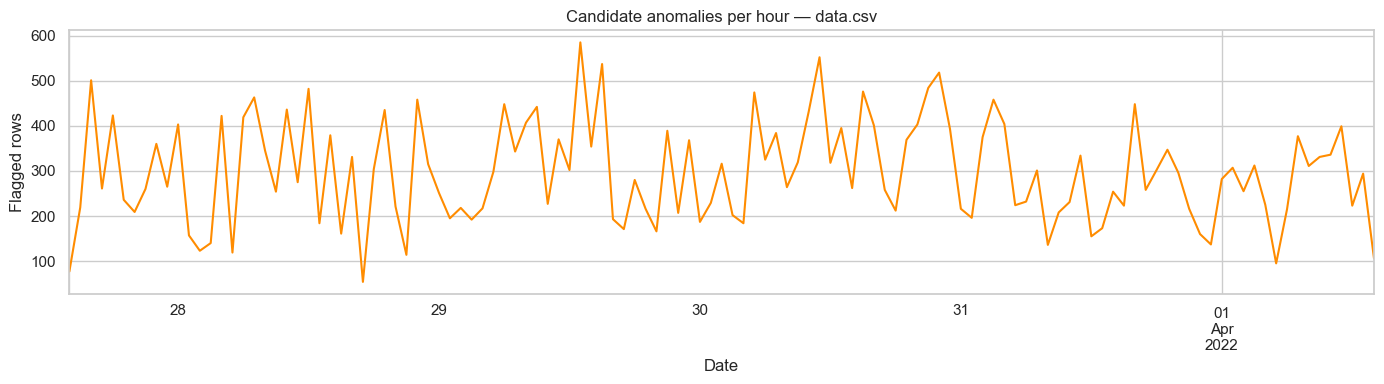

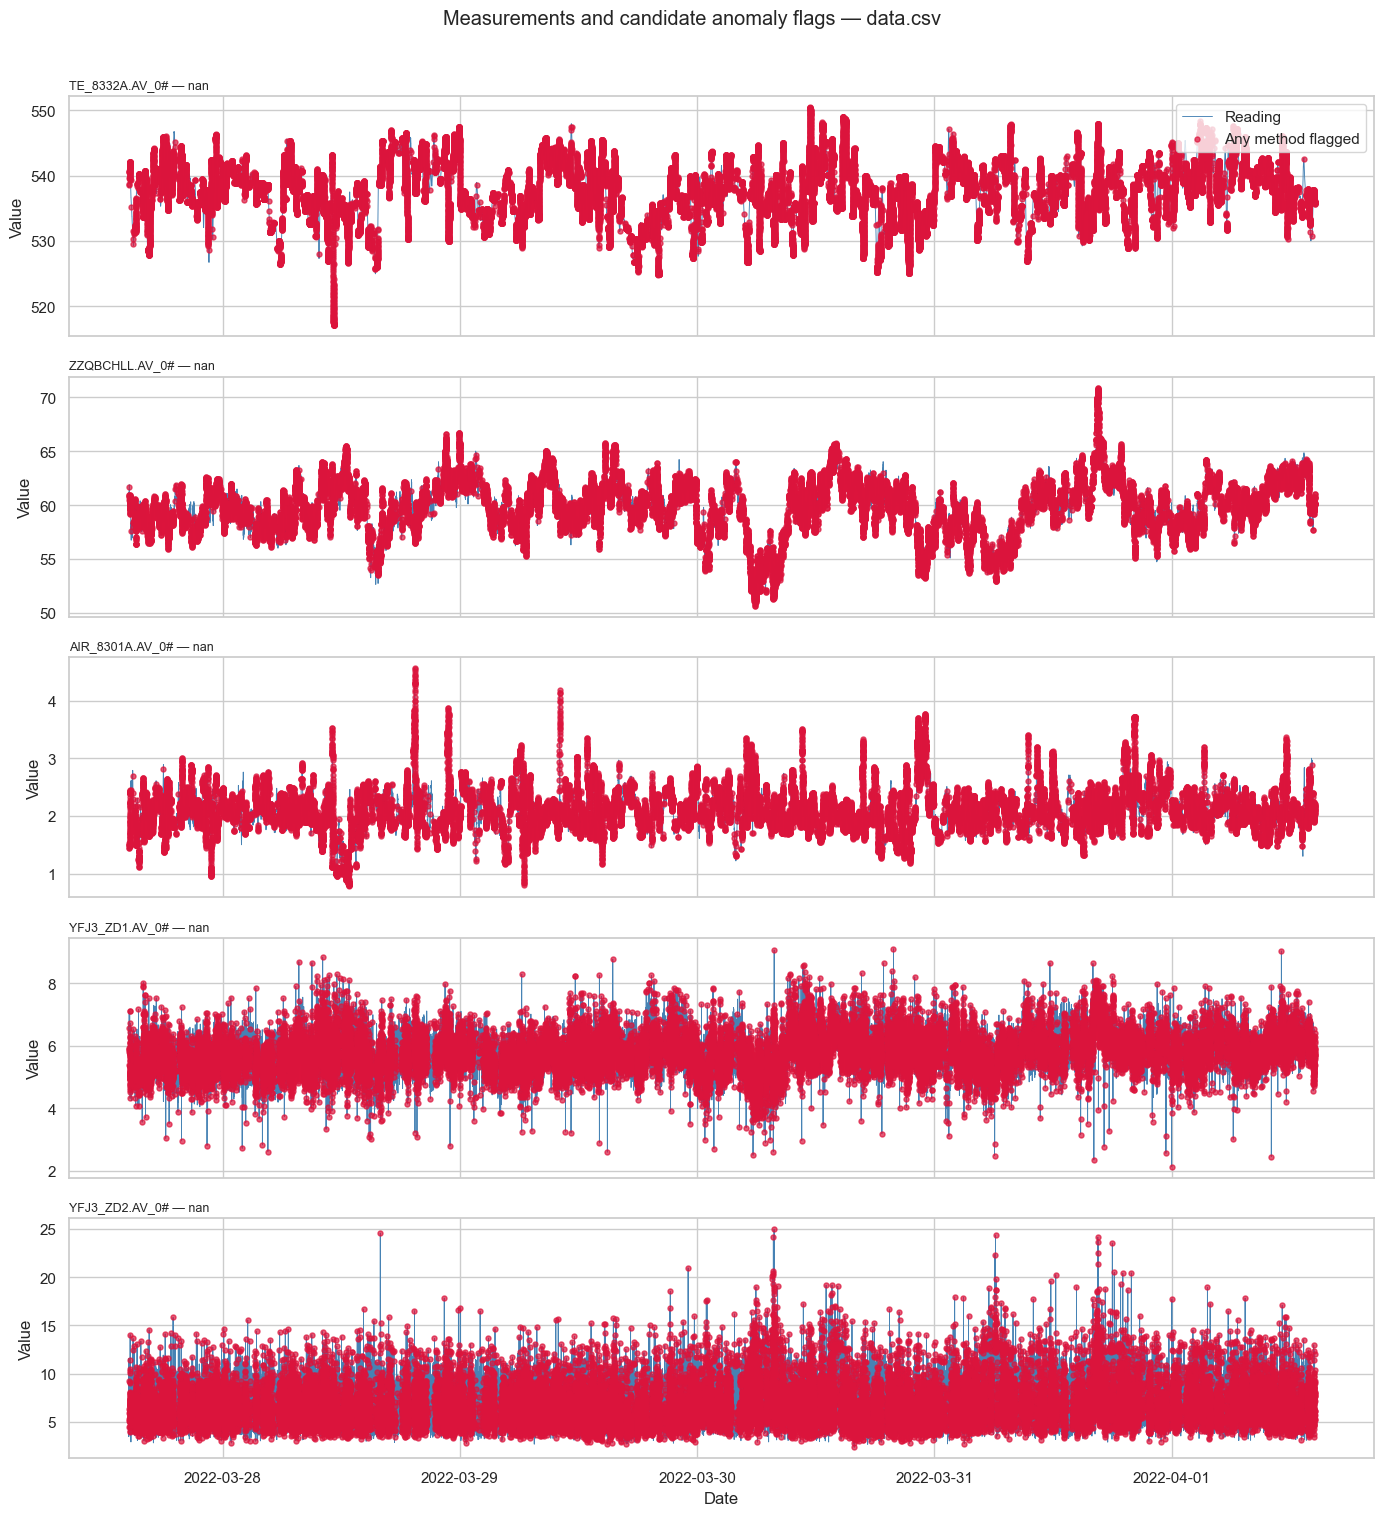

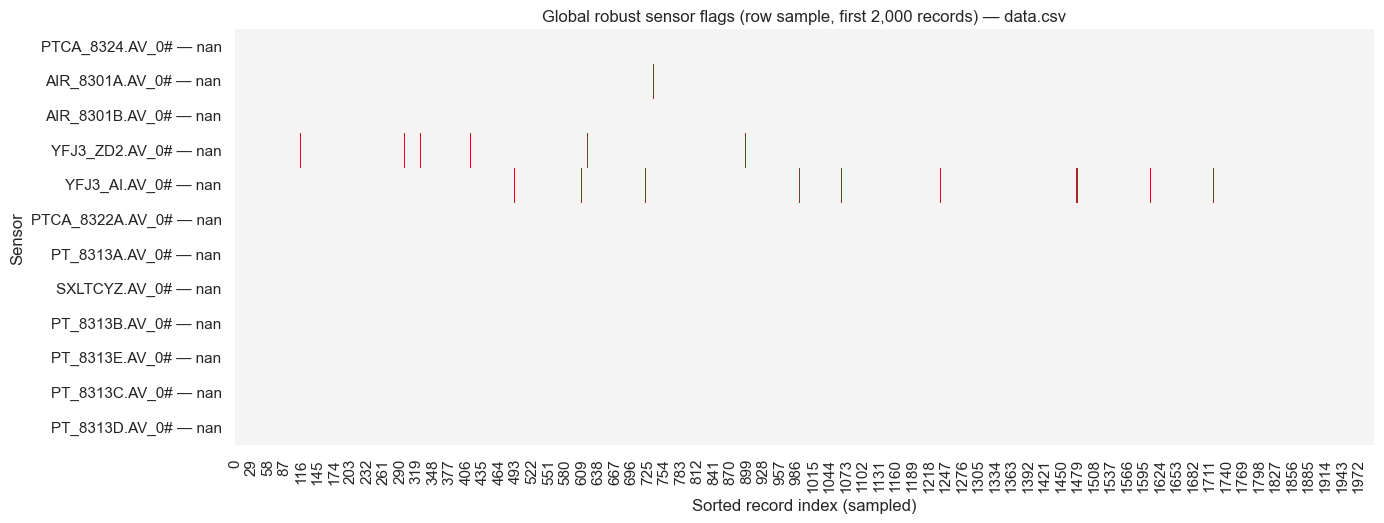

In [16]:
PLOT_DATASET = "data.csv"
plot_result, plot_global, plot_local, plot_scores = detected[PLOT_DATASET]
plot_sensors = data_sensors if PLOT_DATASET == "data.csv" else autoreg_sensors

hourly_flags = plot_result.set_index("date")["any_flag"].resample("h").sum()
fig, ax = plt.subplots(figsize=(14, 4))
hourly_flags.plot(ax=ax, color="darkorange")
ax.set(title=f"Candidate anomalies per hour — {PLOT_DATASET}", xlabel="Date", ylabel="Flagged rows")
plt.tight_layout()
plt.show()

plot_key_map = {canonical_name(c): c for c in plot_sensors}
preferred = ["TE_8332A.AV_0", "ZZQBCHLL.AV_0", "AIR_8301A.AV_0", "YFJ3_ZD1.AV_0", "YFJ3_ZD2.AV_0"]
plot_cols = [plot_key_map[k] for k in preferred if k in plot_key_map]
if not plot_cols:
    plot_cols = plot_sensors[:5]
fig, axes = plt.subplots(len(plot_cols), 1, figsize=(14, 3 * len(plot_cols)), sharex=True)
axes = np.atleast_1d(axes)
for ax, col in zip(axes, plot_cols):
    ax.plot(plot_result["date"], plot_result[col], linewidth=.65, color="steelblue", label="Reading")
    flagged = plot_result["any_flag"]
    ax.scatter(plot_result.loc[flagged, "date"], plot_result.loc[flagged, col],
               s=13, color="crimson", alpha=.7, label="Any method flagged", zorder=3)
    description = sensor_descriptions.get(canonical_name(col), col)
    ax.set_title(f"{col} — {description}", loc="left", fontsize=9)
    ax.set_ylabel("Value")
axes[0].legend(loc="upper right")
axes[-1].set_xlabel("Date")
fig.suptitle(f"Measurements and candidate anomaly flags — {PLOT_DATASET}", y=1.01)
plt.tight_layout()
plt.show()

top_sensors = plot_global.sum().sort_values(ascending=False).head(12).index
flag_matrix = plot_global[top_sensors].astype(int).iloc[:2000].T
flag_matrix.index = [
    f"{col} — {sensor_descriptions.get(canonical_name(col), 'No catalog description')}" for col in flag_matrix.index
]
plt.figure(figsize=(14, max(4, .45 * len(top_sensors))))
sns.heatmap(flag_matrix, cmap=sns.color_palette(["#f4f4f4", "#b22222"], as_cmap=True), cbar=False)
plt.title(f"Global robust sensor flags (row sample, first 2,000 records) — {PLOT_DATASET}")
plt.xlabel("Sorted record index (sampled)")
plt.ylabel("Sensor")
plt.tight_layout()
plt.show()

## 6. Compare anomaly candidates between datasets

Because both files appear to share a schema, compare matched timestamps and values before assuming they should have identical flags. Differences may be preprocessing-related. We report overlap only where normalized sensor names and timestamps align; if duplicate timestamps exist, readings are averaged before merging.

In [18]:
detected_data = detected["data.csv"][0]
detected_autoreg = detected["data_AutoReg.csv"][0]
shared_sensors = sorted(
    {canonical_name(c) for c in data_sensors}
    & {canonical_name(c) for c in autoreg_sensors}
)
left_cols = {canonical_name(c): c for c in data_sensors}
right_cols = {canonical_name(c): c for c in autoreg_sensors}

if shared_sensors:
    left = detected_data[["date", "any_flag"] + [left_cols[k] for k in shared_sensors]].copy()
    right = detected_autoreg[["date", "any_flag"] + [right_cols[k] for k in shared_sensors]].copy()
    left.columns = ["date", "data_flag"] + [f"{k}_data" for k in shared_sensors]
    right.columns = ["date", "autoreg_flag"] + [f"{k}_autoreg" for k in shared_sensors]
    left = left.groupby("date", as_index=False).agg({c: "mean" for c in left.columns if c != "date"})
    right = right.groupby("date", as_index=False).agg({c: "mean" for c in right.columns if c != "date"})
    paired = left.merge(right, on="date", how="inner")
    print(f"Shared sensor names: {len(shared_sensors)}; matched timestamps: {len(paired):,}")
    if not paired.empty:
        paired["data_flag"] = paired["data_flag"].gt(0)
        paired["autoreg_flag"] = paired["autoreg_flag"].gt(0)
        paired["both_flagged"] = paired["data_flag"] & paired["autoreg_flag"]
        paired["only_data_flagged"] = paired["data_flag"] & ~paired["autoreg_flag"]
        paired["only_autoreg_flagged"] = paired["autoreg_flag"] & ~paired["data_flag"]
        paired_summary = pd.DataFrame({
            "comparison": ["Both datasets flagged", "Only data.csv flagged", "Only data_AutoReg.csv flagged"],
            "matched_rows": [paired.both_flagged.sum(), paired.only_data_flagged.sum(), paired.only_autoreg_flagged.sum()],
        })
        paired_summary["percent_of_matched_rows"] = (paired_summary.matched_rows / len(paired) * 100).round(3)
        display(paired_summary)
        differences = []
        for key in shared_sensors:
            x, y = paired[f"{key}_data"], paired[f"{key}_autoreg"]
            valid = x.notna() & y.notna()
            if valid.any():
                differences.append({
                    "sensor": key,
                    "description": sensor_descriptions.get(key, "Not in columns.csv"),
                    "paired_values": int(valid.sum()),
                    "mean_absolute_difference": (x[valid] - y[valid]).abs().mean(),
                    "identical_fraction": (np.isclose(x[valid], y[valid], equal_nan=True)).mean(),
                })
        difference_table = pd.DataFrame(differences).sort_values("mean_absolute_difference", ascending=False)
        print("Largest value differences on matched timestamps:")
        display(difference_table.head(12))
else:
    print("There are no shared varying numeric sensor columns to compare.")

Shared sensor names: 30; matched timestamps: 86,400


,comparison,matched_rows,percent_of_matched_rows
0,Both datasets flagged,35879,41.527
1,Only data.csv flagged,10,0.012
2,Only data_AutoReg.csv flagged,0,0.000


Largest value differences on matched timestamps:


,sensor,description,paired_values,mean_absolute_difference,identical_fraction
0,AIR_8301A.AV_0,NaN,86400,0.0,1.0
1,AIR_8301B.AV_0,NaN,86400,0.0,1.0
2,FT_8301.AV_0,NaN,86400,0.0,1.0
3,FT_8302.AV_0,NaN,86400,0.0,1.0
4,FT_8306A.AV_0,NaN,86400,0.0,1.0
5,FT_8306B.AV_0,NaN,86400,0.0,1.0
6,PTCA_8322A.AV_0,NaN,86400,0.0,1.0
7,PTCA_8324.AV_0,NaN,86400,0.0,1.0
8,PT_8313A.AV_0,NaN,86400,0.0,1.0
9,PT_8313B.AV_0,NaN,86400,0.0,1.0


## 7. Data-driven review notes

Use this summary to prioritize investigation. Validate detections with sensor calibration, maintenance records, operating modes, control actions, and domain-approved limits before taking action.

In [19]:
for name, (result, global_flags, local_flags, _) in detected.items():
    print(f"{name}: {len(result):,} timestamped rows; "
          f"{result.any_flag.sum():,} ({result.any_flag.mean():.2%}) flagged by one or more screens; "
          f"{result.isolation_forest_flag.sum():,} flagged by Isolation Forest.")
    top_global = global_flags.sum().sort_values(ascending=False)
    top_global = top_global[top_global > 0].head(3)
    if not top_global.empty:
        labels = [
            f"{sensor_descriptions.get(canonical_name(col), col)} ({int(count)} readings)"
            for col, count in top_global.items()
        ]
        print("  Most frequent global outlier sensors:", "; ".join(labels))
    else:
        print("  No global outlier flags under the selected robust thresholds.")

print("\nCaveats: rolling-window results depend on the chosen window and timestamp regularity. Global distribution screens can flag legitimate operating-regime transitions. Isolation Forest is sensitive to feature availability and the configured contamination rate. None of these methods substitutes for validated alarm limits or engineering review.")

data.csv: 86,400 timestamped rows; 35,889 (41.54%) flagged by one or more screens; 864 flagged by Isolation Forest.
  Most frequent global outlier sensors: nan (1832 readings); nan (1604 readings); nan (1265 readings)
data_AutoReg.csv: 86,400 timestamped rows; 35,879 (41.53%) flagged by one or more screens; 864 flagged by Isolation Forest.
  Most frequent global outlier sensors: nan (1832 readings); nan (1604 readings); nan (1265 readings)

Caveats: rolling-window results depend on the chosen window and timestamp regularity. Global distribution screens can flag legitimate operating-regime transitions. Isolation Forest is sensitive to feature availability and the configured contamination rate. None of these methods substitutes for validated alarm limits or engineering review.
